# What is the X data worth? Results of the one-shot 2025+ test

Frozen design: `docs/x_utility_spec.md`, commit `4ec0b2a`, set before any X data met a 2025+ outcome.
This notebook only reads saved results from `data/X_derived/x_utility/`; nothing is fitted here. The
models are in `h5n1/models/x_utility.py` (Track A) and `h5n1/models/x_sightings.py` (Track B).

**Neither primary met its success rule.** Train and test features come from different collectors, so
every 2025+ number here carries that label. These are public and news posts, not farmer posts.

In [1]:
import pathlib

import matplotlib.pyplot as plt
import pandas as pd

R = pathlib.Path("..") / "data" / "X_derived" / "x_utility"
pd.set_option("display.max_columns", 30, "display.width", 180)
BLUE, ORANGE, INK, MUTED, GRID, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
lift = pd.read_csv(R / "final_lift.csv")
sight = pd.read_csv(R / "final_sightings.csv")
explore_a = pd.read_csv(R / "explore_lift_reduced.csv")
explore_b = pd.read_csv(R / "sightings_gap_explore.csv")

## Primary results

| Track | Primary | Result | 95% CI | Rule | Outcome |
|---|---|---|---|---|---|
| A | S4 − S3 PR-AUC, k=14, state new-onset | +0.0079 | −0.0060 to +0.0212 | CI above 0, and positive under the 5-day embargo | **Not met** |
| B | O/E ratio, k=14, all sightings | 0.85 | 0.67 to 1.09 | CI above 1, and above 1 with the 5-day gap | **Not met** |

Track A's largest PR-AUC gain the data allow is about 0.021 on a base of 0.346. Track B's data rule out
sighting weeks running more than about 9% above expected.

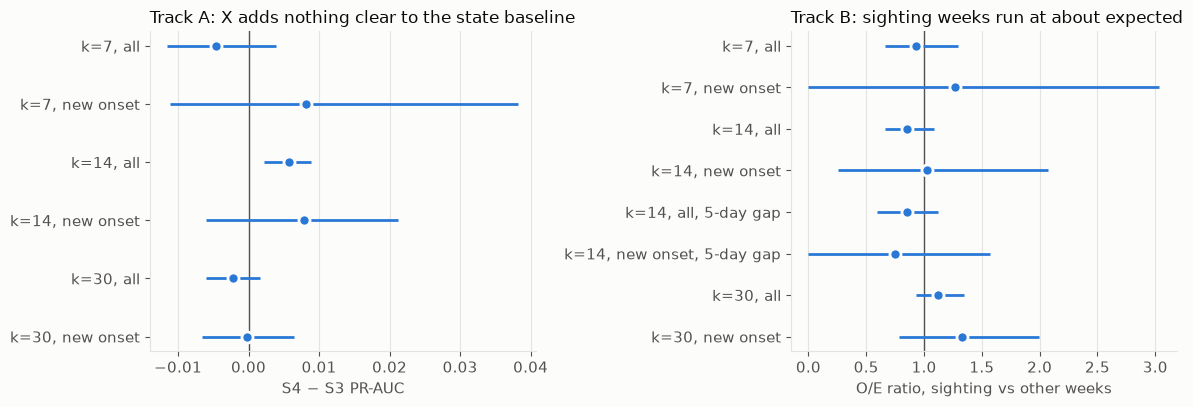

,label,rows,positives,pr_auc_ref,pr_auc_new,delta,d_lo,d_hi
1,"k=7, all",1719,284,0.5464,0.5418,-0.0046,-0.0115,0.0039
5,"k=7, new onset",1052,74,0.2315,0.2397,0.0082,-0.0111,0.0382
45,"k=14, all",1710,428,0.6191,0.6249,0.0058,0.0022,0.0089
49,"k=14, new onset",1043,135,0.3458,0.3538,0.0079,-0.0060,0.0212
89,"k=30, all",1665,619,0.7250,0.7229,-0.0022,-0.0060,0.0016
93,"k=30, new onset",1002,231,0.5628,0.5626,-0.0002,-0.0066,0.0064


In [2]:
def forest(ax, rows, x, lo, hi, null, xlabel, title):
    y = list(range(len(rows)))[::-1]
    ax.axvline(null, color=MUTED, lw=1)
    ax.hlines(y, rows[lo], rows[hi], color=BLUE, lw=2)
    ax.scatter(rows[x], y, s=64, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.set_yticks(y, rows["label"])
    ax.set_xlabel(xlabel)
    ax.set_title(title, loc="left", fontsize=12, color=INK)
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)


a = lift[(lift.variant == "primary") & (lift.comparison == "S4 vs S3")].copy()
a["label"] = "k=" + a.k.astype(str) + ", " + a.slice.map({"all": "all", "state_new_onset": "new onset"})
b = sight[(sight.period == "all")].copy()
b["label"] = "k=" + b.k.astype(str) + ", " + b.slice.map({"all": "all", "state_new_onset": "new onset"}) \
    + b.gap_days.map({0: "", 5: ", 5-day gap"})
fig, (l, r) = plt.subplots(1, 2, figsize=(12, 4.2))
forest(l, a, "delta", "d_lo", "d_hi", 0, "S4 − S3 PR-AUC", "Track A: X adds nothing clear to the state baseline")
forest(r, b, "oe_ratio", "ratio_lo", "ratio_hi", 1, "O/E ratio, sighting vs other weeks", "Track B: sighting weeks run at about expected")
fig.tight_layout()
plt.show()
pd.concat([a[["label", "rows", "positives", "pr_auc_ref", "pr_auc_new", "delta", "d_lo", "d_hi"]]]).round(4)

In [3]:
b[["label", "sightings", "followed", "trigger_rate", "expected", "oe_ratio", "ratio_lo", "ratio_hi",
   "matched_rate", "share_flagged"]].round(3)

,label,sightings,followed,trigger_rate,expected,oe_ratio,ratio_lo,ratio_hi,matched_rate,share_flagged
0,"k=7, all",62,18,0.290,18.517,0.934,0.664,1.293,0.236,0.039
3,"k=7, new onset",22,3,0.136,2.460,1.272,0.000,3.036,0.145,0.022
4,"k=14, all",62,22,0.355,25.894,0.852,0.666,1.085,0.345,0.031
7,"k=14, new onset",22,4,0.182,4.014,1.024,0.257,2.075,0.232,0.016
8,"k=14, all, 5-day gap",62,15,0.242,17.299,0.850,0.593,1.123,0.228,0.034
11,"k=14, new onset, 5-day gap",22,2,0.091,2.727,0.753,0.000,1.566,0.169,0.013
12,"k=30, all",62,38,0.613,33.338,1.119,0.929,1.349,0.460,0.035
15,"k=30, new onset",22,9,0.409,6.671,1.332,0.781,1.998,0.346,0.019


## Track A: every arm, 2025+

X alone (S1) barely beats the base rate. S2 is below S0, so X scores worse than season and place, and
S4 is about equal to S3. That is the "no detectable signal" reading from the spec.

In [4]:
p = lift[lift.variant == "primary"].drop_duplicates(["k", "slice"])
p[["k", "slice", "base_rate", "pr_auc_S0", "pr_auc_S1", "pr_auc_S2", "pr_auc_S3", "pr_auc_S4", "pr_auc_S4v",
   "pr_auc_S4s"]].round(4)

,k,slice,base_rate,pr_auc_S0,pr_auc_S1,pr_auc_S2,pr_auc_S3,pr_auc_S4,pr_auc_S4v,pr_auc_S4s
0,7,all,0.1652,0.3422,0.1736,0.3068,0.5464,0.5418,0.5449,0.5468
4,7,state_new_onset,0.0703,0.1993,0.0711,0.1602,0.2315,0.2397,0.2353,0.2245
44,14,all,0.2503,0.4793,0.2550,0.4566,0.6191,0.6249,0.6193,0.6219
48,14,state_new_onset,0.1294,0.2934,0.1298,0.2711,0.3458,0.3538,0.3512,0.3475
88,30,all,0.3718,0.6543,0.3735,0.6326,0.7250,0.7229,0.7263,0.7234
92,30,state_new_onset,0.2305,0.4846,0.2326,0.4724,0.5628,0.5626,0.5654,0.5614


**Secondary, no multiplicity correction.** At k=14 on all rows, S4 − S3 is +0.0058 and its CI excludes
0, but the gain is about 0.6 points of PR-AUC and falls to +0.0004 under the 5-day embargo, which is
what an announcement effect would look like. Permutation p-values and shared/unique deviance follow.

In [5]:
dev = pd.read_csv(R / "final_deviance.csv").drop(columns=["variant", "spec_commit"])
perm = pd.read_csv(R / "final_permutation.csv").drop(columns="spec_commit")
display(perm.round(4))
dev.round(4)

,k,slice,observed,null_mean,gain,p
0,7,all,0.5418,0.5461,-0.0043,0.9867
1,7,state_new_onset,0.2397,0.2434,-0.0037,0.6711
2,14,all,0.6249,0.6242,0.0007,0.1761
3,14,state_new_onset,0.3538,0.3532,0.0006,0.3887
4,30,all,0.7229,0.7233,-0.0004,0.6512
5,30,state_new_onset,0.5626,0.5632,-0.0005,0.7076


,k,slice,d2_baseline,d2_x,d2_both,unique_baseline,unique_x,shared
0,7,all,0.2467,0.0001,0.2468,0.2467,0.0001,0.0000
1,7,state_new_onset,0.1355,0.0002,0.1360,0.1359,0.0006,-0.0004
2,14,all,0.2385,0.0000,0.2385,0.2385,0.0000,-0.0000
3,14,state_new_onset,0.1589,0.0003,0.1595,0.1592,0.0006,-0.0003
4,30,all,0.2554,0.0001,0.2555,0.2554,0.0001,0.0000
5,30,state_new_onset,0.2042,0.0006,0.2044,0.2039,0.0002,0.0003


In [6]:
off = pd.read_csv(R / "final_offset.csv")
off[off.model != "joint"][["k", "slice", "term", "or_per_sd", "se", "p"]].round(3)

,k,slice,term,or_per_sd,se,p
0,7,all,x_share_7d,1.050,0.036,0.179
1,7,all,x_sent_7d,0.951,0.096,0.597
2,7,all,x_sent_chg,0.967,0.061,0.581
7,7,state_new_onset,x_share_7d,1.105,0.057,0.077
8,7,state_new_onset,x_sent_7d,1.133,0.145,0.389
9,7,state_new_onset,x_sent_chg,1.118,0.148,0.451
14,14,all,x_share_7d,1.042,0.047,0.383
15,14,all,x_sent_7d,1.041,0.088,0.651
16,14,all,x_sent_chg,1.045,0.068,0.520
21,14,state_new_onset,x_share_7d,1.118,0.059,0.056


## Periods and coverage

Results for 2025-Q1 and later weeks, as the spec requires. Sighting weeks in 2025-Q1 ran **below**
expected (ratio 0.70, CI 0.53 to 0.91). X also misses much of the outbreak record: about 61% of
outbreak-followed state-weeks at k=14 are on covered rows, and 53% for new onsets.

In [7]:
w = lift[lift.variant.isin(["primary", "first_quarter", "later_weeks"]) & (lift.comparison == "S4 vs S3") & (lift.k == 14)]
display(w[["variant", "slice", "rows", "positives", "delta", "d_lo", "d_hi"]].round(4))
display(sight[(sight.k == 14) & (sight.gap_days == 0)][["slice", "period", "sightings", "followed", "oe_ratio", "ratio_lo", "ratio_hi"]].round(3))
pd.read_csv(R / "final_coverage.csv").drop(columns="spec_commit").round(3)

,variant,slice,rows,positives,delta,d_lo,d_hi
45,primary,all,1710,428,0.0058,0.0022,0.0089
49,primary,state_new_onset,1043,135,0.0079,-0.0060,0.0212
53,first_quarter,all,547,205,0.0042,-0.0003,0.0076
57,first_quarter,state_new_onset,227,46,0.0074,-0.0032,0.0201
61,later_weeks,all,1163,223,0.0043,-0.0009,0.0089
65,later_weeks,state_new_onset,816,89,0.0071,-0.0113,0.0277


,slice,period,sightings,followed,oe_ratio,ratio_lo,ratio_hi
4,all,all,62,22,0.852,0.666,1.085
5,all,first_quarter,34,13,0.697,0.531,0.908
6,all,later_weeks,28,9,1.062,0.592,1.609
7,state_new_onset,all,22,4,1.024,0.257,2.075


,k,slice,state_weeks,covered_rows,positive_state_weeks,positives_on_covered,share_positives_covered
0,7,all,3871,1719,459,284,0.619
1,7,state_new_onset,2714,1052,138,74,0.536
2,14,all,3822,1710,703,428,0.609
3,14,state_new_onset,2670,1043,254,135,0.531
4,30,all,3675,1665,1086,619,0.570
5,30,state_new_onset,2538,1002,470,231,0.491


## Exploration did not replicate

Sighting weeks looked about 20% above expected in 2022-24; on 2025+ they did not. This is why the test
was held out. The exploration values were not used as a prior.

In [8]:
pd.DataFrame({"": ["Track A, primary", "Track B, primary"],
              "2022-24 folds": [explore_a.query("k == 14 and slice == 'state_new_onset' and comparison == 'S4 vs S3'").delta.iloc[0],
                                explore_b.query("gap_days == 0 and slice == 'all'").oe_ratio.iloc[0]],
              "2025+ test": [a.query("k == 14 and slice == 'state_new_onset'").delta.iloc[0],
                             b.query("k == 14 and gap_days == 0 and slice == 'all'").oe_ratio.iloc[0]]}).round(4)

,,2022-24 folds,2025+ test
0,"Track A, primary",0.0049,0.0079
1,"Track B, primary",1.2225,0.8516


## When does X move, relative to a state onset? (2022-24)

Exploration window, covered state-weeks. X volume is flat before an onset, jumps in the onset week and
fades after it. That is the shape of a reaction, not a warning.

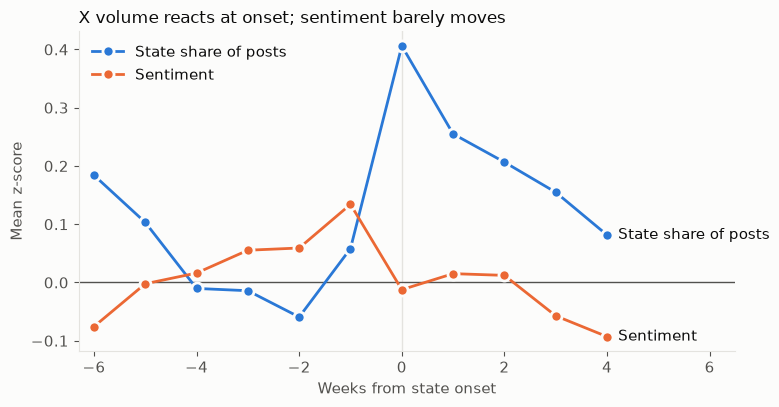

,weeks_from_onset,rows,x_share_7d,x_sent_7d
0,-6,146,0.184,-0.076
1,-5,143,0.103,-0.002
2,-4,152,-0.010,0.016
3,-3,154,-0.014,0.055
4,-2,161,-0.059,0.059
5,-1,170,0.058,0.134
6,0,171,0.406,-0.012
7,1,178,0.255,0.015
8,2,173,0.207,0.012
9,3,166,0.155,-0.057


In [9]:
et = pd.read_csv(R / "event_time.csv")
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.axvline(0, color=GRID, lw=1)
ax.axhline(0, color=MUTED, lw=1)
for col, c, name in [("x_share_7d", BLUE, "State share of posts"), ("x_sent_7d", ORANGE, "Sentiment")]:
    ax.plot(et.weeks_from_onset, et[col], color=c, lw=2, marker="o", ms=8, mec=SURFACE, mew=2, label=name)
    ax.annotate(name, (et.weeks_from_onset.iloc[-1], et[col].iloc[-1]), xytext=(8, 0), textcoords="offset points",
                color=INK, va="center")
ax.legend(frameon=False, loc="upper left")
ax.set_xlabel("Weeks from state onset")
ax.set_ylabel("Mean z-score")
ax.set_title("X volume reacts at onset; sentiment barely moves", loc="left", fontsize=12, color=INK)
ax.set_xlim(-6.3, 6.5)
fig.tight_layout()
plt.show()
et[["weeks_from_onset", "rows", "x_share_7d", "x_sent_7d"]].round(3)

## County baseline (C3), no X

Waree's forest on 35 features, trained through 2024, on every CONUS county-day of 2025+.

In [10]:
pd.read_csv(R / "county_c3_2025.csv").round(4)

,k,slice,test_rows,positives,base_rate,pr_auc,lift_x,roc
0,7,all,1715616,4360,0.0025,0.1426,56.1082,0.8775
1,7,new_onset,1682786,2973,0.0018,0.0160,9.0493,0.8341
2,14,all,1693860,7795,0.0046,0.1299,28.2342,0.8624
3,14,new_onset,1661101,5797,0.0035,0.0269,7.7047,0.8283
4,30,all,1644132,14596,0.0089,0.1311,14.7711,0.8408
5,30,new_onset,1611569,11758,0.0073,0.0462,6.3305,0.8156
